In [1]:
# ============================================================
# 1. Imports
# ============================================================

import os

os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.0"

import glob
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

# ============================================================
# 2. Dataset path
# ============================================================

DATA_PATH = "./GEFCom2014-L_V2/Load"


tasks = sorted(
    glob.glob(DATA_PATH + "/Task */L*-train.csv")
)

print("Number of tasks:", len(tasks))

Number of tasks: 15


In [2]:
def parse_gefcom_time(x):

    x = str(x).strip()

    date_part, time_part = x.split()

    hour = int(time_part.split(":")[0])

    year = int(date_part[-4:])

    md = date_part[:-4]


    if len(md) == 2:

        month = int(md[0])
        day = int(md[1])


    elif len(md) == 3:

        month = int(md[0])
        day = int(md[1:])


    elif len(md) == 4:

        month = int(md[:2])
        day = int(md[2:])


    else:

        raise ValueError(
            f"Unknown timestamp format {x}"
        )


    return pd.Timestamp(
        year=year,
        month=month,
        day=day,
        hour=hour
    )

In [3]:
all_data = []


for file in tasks:

    temp = pd.read_csv(file)


    temp["TIMESTAMP"] = (
        temp["TIMESTAMP"]
        .apply(parse_gefcom_time)
    )


    all_data.append(temp)

In [4]:
import numpy as np
import pandas as pd


# combine all tasks
df = pd.concat(
    all_data,
    ignore_index=True
)


# sort properly
df = df.sort_values(
    [
        "ZONEID",
        "TIMESTAMP"
    ]
)


# remove exact duplicates only
df = df.drop_duplicates(
    subset=[
        "ZONEID",
        "TIMESTAMP"
    ],
    keep="last"
)


print(
    "Before hourly aggregation:",
    df.shape
)


# If multiple zones exist, keep separate
print(
    "Zones:",
    df["ZONEID"].unique()
)


# choose one zone for now
zone = df["ZONEID"].iloc[0]


df = df[
    df["ZONEID"] == zone
]


# hourly aggregation

weather_cols = [
    f"w{i}"
    for i in range(1,26)
]


df_hourly = (
    df
    .set_index("TIMESTAMP")
    .resample("1h")
    .agg(
        {
            "LOAD":"mean",
            **{
                c:"mean"
                for c in weather_cols
            }
        }
    )
)


df_hourly = df_hourly.reset_index()


print(
    "After hourly:",
    df_hourly.shape
)


print(
    df_hourly.isna().sum()
)

Before hourly aggregation: (88752, 28)
Zones: [1]
After hourly: (95664, 27)
TIMESTAMP        0
LOAD         39384
w1            6912
w2            6912
w3            6912
w4            6912
w5            6912
w6            6912
w7            6912
w8            6912
w9            6912
w10           6912
w11           6912
w12           6912
w13           6912
w14           6912
w15           6912
w16           6912
w17           6912
w18           6912
w19           6912
w20           6912
w21           6912
w22           6912
w23           6912
w24           6912
w25           6912
dtype: int64


In [5]:
# interpolate weather only

weather_cols = [
    f"w{i}"
    for i in range(1,26)
]


df_hourly[weather_cols] = (
    df_hourly[weather_cols]
    .interpolate(
        method="linear"
    )
)


# keep only rows where load exists

df_hourly = (
    df_hourly
    .dropna(
        subset=["LOAD"]
    )
)


df_hourly = (
    df_hourly
    .reset_index(drop=True)
)


print(
    df_hourly.shape
)


print(
    df_hourly.isna().sum()
)

(56280, 27)
TIMESTAMP    0
LOAD         0
w1           0
w2           0
w3           0
w4           0
w5           0
w6           0
w7           0
w8           0
w9           0
w10          0
w11          0
w12          0
w13          0
w14          0
w15          0
w16          0
w17          0
w18          0
w19          0
w20          0
w21          0
w22          0
w23          0
w24          0
w25          0
dtype: int64


In [6]:
time_diff = df_hourly["TIMESTAMP"].diff()

print(
    time_diff.value_counts().head()
)

TIMESTAMP
0 days 01:00:00    56259
9 days 01:00:00       20
Name: count, dtype: int64


In [7]:
# ==============================
# Calendar Feature Engineering
# ==============================

df_hourly["hour"] = (
    df_hourly["TIMESTAMP"]
    .dt.hour
)


df_hourly["dayofweek"] = (
    df_hourly["TIMESTAMP"]
    .dt.dayofweek
)


df_hourly["month"] = (
    df_hourly["TIMESTAMP"]
    .dt.month
)


# cyclic encoding

df_hourly["hour_sin"] = np.sin(
    2*np.pi*df_hourly["hour"]/24
)

df_hourly["hour_cos"] = np.cos(
    2*np.pi*df_hourly["hour"]/24
)


df_hourly["dow_sin"] = np.sin(
    2*np.pi*df_hourly["dayofweek"]/7
)

df_hourly["dow_cos"] = np.cos(
    2*np.pi*df_hourly["dayofweek"]/7
)


df_hourly["month_sin"] = np.sin(
    2*np.pi*df_hourly["month"]/12
)

df_hourly["month_cos"] = np.cos(
    2*np.pi*df_hourly["month"]/12
)


print(
    df_hourly[
        [
            "hour_sin",
            "hour_cos",
            "dow_sin",
            "dow_cos",
            "month_sin",
            "month_cos"
        ]
    ].head()
)

   hour_sin  hour_cos   dow_sin   dow_cos  month_sin  month_cos
0  0.000000  1.000000 -0.974928 -0.222521        0.5   0.866025
1  0.258819  0.965926 -0.974928 -0.222521        0.5   0.866025
2  0.500000  0.866025 -0.974928 -0.222521        0.5   0.866025
3  0.707107  0.707107 -0.974928 -0.222521        0.5   0.866025
4  0.866025  0.500000 -0.974928 -0.222521        0.5   0.866025


In [8]:
# ==============================
# Train / Validation / Test Split
# ==============================

n = len(df_hourly)


train_end = int(
    0.70 * n
)


val_end = int(
    0.85 * n
)


# keep history context for validation and test
train_df = df_hourly.iloc[
    :train_end
].copy()


val_df = df_hourly.iloc[
    train_end-168:val_end
].copy()


test_df = df_hourly.iloc[
    val_end-168:
].copy()



print(
    "Train:",
    train_df.shape
)


print(
    "Validation:",
    val_df.shape
)


print(
    "Test:",
    test_df.shape
)

Train: (39396, 36)
Validation: (8610, 36)
Test: (8610, 36)


In [9]:
# ==============================
# Scaling
# ==============================

from sklearn.preprocessing import StandardScaler


load_scaler = StandardScaler()

weather_scaler = StandardScaler()



# ---- LOAD scaling ----

train_df["LOAD_scaled"] = (
    load_scaler
    .fit_transform(
        train_df[["LOAD"]]
    )
    .astype(np.float32)
)


val_df["LOAD_scaled"] = (
    load_scaler
    .transform(
        val_df[["LOAD"]]
    )
    .astype(np.float32)
)


test_df["LOAD_scaled"] = (
    load_scaler
    .transform(
        test_df[["LOAD"]]
    )
    .astype(np.float32)
)



# ---- Weather scaling ----

weather_features = [
    f"w{i}"
    for i in range(1,26)
]


train_weather = weather_scaler.fit_transform(
    train_df[weather_features]
)


val_weather = weather_scaler.transform(
    val_df[weather_features]
)


test_weather = weather_scaler.transform(
    test_df[weather_features]
)



for i, col in enumerate(weather_features):

    train_df[col+"_scaled"] = (
        train_weather[:,i]
    )


    val_df[col+"_scaled"] = (
        val_weather[:,i]
    )


    test_df[col+"_scaled"] = (
        test_weather[:,i]
    )



print(
    train_df.head()
)

            TIMESTAMP  LOAD    w1    w2    w3    w4    w5    w6    w7    w8  \
0 2005-01-01 00:00:00  96.7  66.0  66.0  54.0  63.0  70.0  64.0  66.0  68.0   
1 2005-01-01 01:00:00  87.0  66.0  64.0  53.0  62.0  70.0  64.0  67.0  68.0   
2 2005-01-01 02:00:00  80.8  66.0  63.0  55.0  62.0  68.0  64.0  67.0  66.0   
3 2005-01-01 03:00:00  78.2  64.0  63.0  56.0  62.0  68.0  64.0  67.0  66.0   
4 2005-01-01 04:00:00  76.6  64.0  63.0  56.0  62.0  68.0  64.0  66.0  64.0   

   ...  w16_scaled  w17_scaled  w18_scaled  w19_scaled  w20_scaled  \
0  ...    0.250808    0.130556    0.358191   -0.204611    0.444023   
1  ...    0.046931    0.069362    0.358191   -0.204611    0.377374   
2  ...   -0.021028    0.069362    0.430096   -0.204611    0.310726   
3  ...   -0.021028   -0.053025    0.430096   -0.204611    0.244078   
4  ...   -0.021028   -0.053025    0.430096   -0.204611    0.177429   

   w21_scaled  w22_scaled  w23_scaled  w24_scaled  w25_scaled  
0    0.027578    0.113393    0.250361   

In [10]:
class EnergyDataset(torch.utils.data.Dataset):

    def __init__(
        self,
        df,
        history=168,
        horizon=24
    ):

        self.history = history
        self.horizon = horizon


        self.demand = (
            df["LOAD_scaled"]
            .values
            .astype(np.float32)
        )


        weather_cols = [
            f"w{i}_scaled"
            for i in range(1,26)
        ]


        self.weather = (
            df[weather_cols]
            .values
            .astype(np.float32)
        )


        calendar_cols = [
            "hour_sin",
            "hour_cos",
            "dow_sin",
            "dow_cos",
            "month_sin",
            "month_cos"
        ]


        self.calendar = (
            df[calendar_cols]
            .values
            .astype(np.float32)
        )


    def __len__(self):

        return (
            len(self.demand)
            -
            self.history
            -
            self.horizon
            +
            1
        )


    def __getitem__(self, idx):

        x_start = idx
        x_end = idx+self.history


        y_start = x_end
        y_end = y_start+self.horizon



        demand = self.demand[
            x_start:x_end
        ]


        weather = self.weather[
            x_start:x_end
        ]


        calendar = self.calendar[
            x_start:x_end
        ]


        last_day = self.demand[
            x_end-24:x_end
        ]


        target = self.demand[
            y_start:y_end
        ]



        return {

            "demand":
                torch.tensor(
                    demand
                ).unsqueeze(-1),


            "weather":
                torch.tensor(
                    weather
                ),


            "calendar":
                torch.tensor(
                    calendar
                ),


            "last_day":
                torch.tensor(
                    last_day
                ),


            "target":
                torch.tensor(
                    target
                )

        }

In [11]:
train_dataset = EnergyDataset(
    train_df,
    history=168,
    horizon=24
)


val_dataset = EnergyDataset(
    val_df,
    history=168,
    horizon=24
)


test_dataset = EnergyDataset(
    test_df,
    history=168,
    horizon=24
)

In [12]:
import torch 
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)


val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)


test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

In [13]:
class DomainEncoder(nn.Module):

    def __init__(
        self,
        input_dim,
        d_model=32
    ):
        super().__init__()


        self.projection = nn.Linear(
            input_dim,
            d_model
        )


        self.norm = nn.LayerNorm(
            d_model
        )


    def forward(self,x):

        # x:
        # batch, time, features

        x = self.projection(x)

        x = self.norm(x)

        return x

In [14]:
class PositionalEncoding(nn.Module):

    def __init__(
        self,
        d_model,
        max_len=500
    ):

        super().__init__()


        pe = torch.zeros(
            max_len,
            d_model
        )


        position = torch.arange(
            0,
            max_len
        ).unsqueeze(1)


        div_term = torch.exp(
            torch.arange(
                0,
                d_model,
                2
            )
            *
            (-np.log(10000.0)/d_model)
        )


        pe[:,0::2] = torch.sin(
            position*div_term
        )


        pe[:,1::2] = torch.cos(
            position*div_term
        )


        self.register_buffer(
            "pe",
            pe.unsqueeze(0)
        )


    def forward(self,x):

        return x + self.pe[:,:x.size(1)]

In [15]:
class DomainFusion(nn.Module):

    def __init__(
        self,
        d_model=64,
        heads=4
    ):

        super().__init__()


        # weather and calendar gates

        self.weather_gate = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.Sigmoid()
        )


        self.calendar_gate = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.Sigmoid()
        )


        self.attention = nn.MultiheadAttention(
            d_model,
            heads,
            batch_first=True
        )


        self.norm = nn.LayerNorm(
            d_model
        )


        self.dropout = nn.Dropout(0.1)



    def forward(
        self,
        demand,
        weather,
        calendar
    ):


        w_gate = self.weather_gate(
            weather
        )


        c_gate = self.calendar_gate(
            calendar
        )


        # demand is preserved

        x = (
            demand
            +
            w_gate * weather
            +
            c_gate * calendar
        )


        attn,_ = self.attention(
            x,
            x,
            x
        )


        x = self.norm(
            x+self.dropout(attn)
        )


        return x

In [16]:
class DreamFormer(nn.Module):

    def __init__(
        self,
        d_model=64,
        horizon=24
    ):

        super().__init__()


        self.demand_encoder = DomainEncoder(
            1,
            d_model
        )


        self.weather_encoder = DomainEncoder(
            25,
            d_model
        )


        self.calendar_encoder = DomainEncoder(
            6,
            d_model
        )


        self.position = PositionalEncoding(
            d_model
        )


        self.fusion = DomainFusion(
            d_model
        )
        
        self.pool = nn.Linear(
                    d_model,
                    1
        )


        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=256,
            dropout=0.1,
            activation="gelu",
            batch_first=True
        )


        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )


        self.head = nn.Sequential(

            nn.Linear(
                d_model,
                128
            ),

            nn.ReLU(),

            nn.Linear(
                128,
                horizon
            )
        )


    def forward(
        self,
        demand,
        weather,
        calendar,
    ):


        d = self.demand_encoder(
            demand
        )

        w = self.weather_encoder(
            weather
        )

        c = self.calendar_encoder(
            calendar
        )


        d = self.position(d)
        w = self.position(w)
        c = self.position(c)



        x = self.fusion(
            d,
            w,
            c
        )
        
        x = self.transformer(
            x
        )

        weights = torch.softmax(
            self.pool(x),
            dim=1
        )


        x = torch.sum(
            weights * x,
            dim=1
        )


        forecast = self.head(x)

        return forecast

In [17]:
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print(device)


model = DreamFormer().to(device)


batch = next(iter(train_loader))


pred = model(
    batch["demand"].to(device),
    batch["weather"].to(device),
    batch["calendar"].to(device),
    ##batch["last_day"].to(device)
)


print(pred.shape)

mps
torch.Size([64, 24])


In [18]:
import torch.optim as optim

criterion = nn.HuberLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

In [19]:
import time
from tqdm.auto import tqdm

/opt/anaconda3/envs/AI/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [20]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device,
    epoch
):

    model.train()

    total_loss = 0.0


    progress_bar = tqdm(
        loader,
        desc=f"Epoch {epoch} | Training",
        leave=False
    )


    for batch_idx, batch in enumerate(progress_bar):

        demand = batch["demand"].to(device)
        weather = batch["weather"].to(device)
        calendar = batch["calendar"].to(device)

        ##last_day = batch["last_day"].to(device)

        target = batch["target"].to(device)


        optimizer.zero_grad()


        prediction = model(
            demand,
            weather,
            calendar
        )


        loss = criterion(
            prediction,
            target
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )


        optimizer.step()


        total_loss += loss.item()


        avg_loss = total_loss / (batch_idx + 1)


        progress_bar.set_postfix(
            {
                "loss": f"{avg_loss:.5f}",
                "lr": optimizer.param_groups[0]["lr"]
            }
        )


    return total_loss / len(loader)

In [21]:
def evaluate(
    model,
    loader,
    criterion,
    device,
    epoch
):

    model.eval()

    total_loss = 0.0


    progress_bar = tqdm(
        loader,
        desc=f"Epoch {epoch} | Validation",
        leave=False
    )


    with torch.no_grad():

        for batch_idx, batch in enumerate(progress_bar):

            demand = batch["demand"].to(device)

            weather = batch["weather"].to(device)

            calendar = batch["calendar"].to(device)

            ##last_day = batch["last_day"].to(device)

            target = batch["target"].to(device)


            prediction = model(
                demand,
                weather,
                calendar,
                ##last_day
            )


            loss = criterion(
                prediction,
                target
            )


            total_loss += loss.item()


            avg_loss = (
                total_loss /
                (batch_idx+1)
            )


            progress_bar.set_postfix(
                {
                    "loss": f"{avg_loss:.5f}"
                }
            )


    return total_loss / len(loader)

In [24]:
EPOCHS = 20


best_val_loss = float("inf")


history = {
    "train_loss":[],
    "val_loss":[],
    "lr":[]
}


checkpoint_path = "dreamformer_v1_best.pt"



for epoch in range(1, EPOCHS+1):


    start_time = time.time()


    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device,
        epoch
    )


    val_loss = evaluate(
        model,
        val_loader,
        criterion,
        device,
        epoch
    )


    epoch_time = (
        time.time()-start_time
    )


    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )


    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["lr"].append(
        current_lr
    )


    print("\n" + "="*70)

    print(
        f"Epoch [{epoch}/{EPOCHS}]"
    )

    print(
        f"Train Loss : {train_loss:.6f}"
    )

    print(
        f"Val Loss   : {val_loss:.6f}"
    )

    print(
        f"Learning Rate : {current_lr:.8f}"
    )

    print(
        f"Time : {epoch_time:.2f} sec"
    )


    # Save best model

    if val_loss < best_val_loss:


        best_val_loss = val_loss


        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "val_loss":
                    val_loss,
                "train_loss":
                    train_loss
            },
            checkpoint_path
        )


        print(
            f"✓ Best model saved "
            f"(Val Loss: {val_loss:.6f})"
        )


    else:

        print(
            f"No improvement "
            f"(Best: {best_val_loss:.6f})"
        )


    print("="*70)


Epoch [1/20]
Train Loss : 0.062330
Val Loss   : 0.076251
Learning Rate : 0.00010000
Time : 55.61 sec
✓ Best model saved (Val Loss: 0.076251)



Epoch [2/20]
Train Loss : 0.058801
Val Loss   : 0.070990
Learning Rate : 0.00010000
Time : 55.22 sec
✓ Best model saved (Val Loss: 0.070990)



Epoch [3/20]
Train Loss : 0.056077
Val Loss   : 0.073183
Learning Rate : 0.00010000
Time : 55.05 sec
No improvement (Best: 0.070990)



Epoch [4/20]
Train Loss : 0.054056
Val Loss   : 0.070220
Learning Rate : 0.00010000
Time : 56.48 sec
✓ Best model saved (Val Loss: 0.070220)



Epoch [5/20]
Train Loss : 0.052380
Val Loss   : 0.067340
Learning Rate : 0.00010000
Time : 66.34 sec
✓ Best model saved (Val Loss: 0.067340)



Epoch [6/20]
Train Loss : 0.051057
Val Loss   : 0.065287
Learning Rate : 0.00010000
Time : 58.83 sec
✓ Best model saved (Val Loss: 0.065287)


... (7 outputs left out)


Epoch [14/20]
Train Loss : 0.043069
Val Loss   : 0.072722
Learning Rate : 0.00010000
Time : 56.14 sec
No improvement (Best: 0.065287)



Epoch [15/20]
Train Loss : 0.042215
Val Loss   : 0.072013
Learning Rate : 0.00010000
Time : 55.99 sec
No improvement (Best: 0.065287)



Epoch [16/20]
Train Loss : 0.041830
Val Loss   : 0.066635
Learning Rate : 0.00010000
Time : 58.37 sec
No improvement (Best: 0.065287)


KeyboardInterrupt: 

In [26]:
batch = next(iter(val_loader))

demand = batch["demand"].to(device)
weather = batch["weather"].to(device)
calendar = batch["calendar"].to(device)

with torch.no_grad():

    pred = model(
        demand,
        weather,
        calendar
    )


print("Prediction scaled range:")
print(pred.min().item(), pred.max().item())


print("Target scaled range:")
print(batch["target"].min().item(),
      batch["target"].max().item())

Prediction scaled range:
-1.3448283672332764 0.33811724185943604
Target scaled range:
-1.309648871421814 0.17752647399902344


In [27]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [28]:
def predict(
    model,
    loader,
    device
):

    model.eval()

    predictions = []
    actuals = []


    with torch.no_grad():

        for batch in loader:

            demand = batch["demand"].to(device)

            weather = batch["weather"].to(device)

            calendar = batch["calendar"].to(device)

            ##last_day = batch["last_day"].to(device)

            target = batch["target"]


            output = model(
                demand,
                weather,
                calendar,
                ##last_day
            )


            predictions.append(
                output.cpu().numpy()
            )


            actuals.append(
                target.numpy()
            )


    predictions = np.concatenate(
        predictions,
        axis=0
    )


    actuals = np.concatenate(
        actuals,
        axis=0
    )


    return predictions, actuals

In [29]:
checkpoint = torch.load(
    "dreamformer_v1_best.pt",
    map_location=device
)


model.load_state_dict(
    checkpoint["model_state_dict"]
)


print(
    "Loaded epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation loss:",
    checkpoint["val_loss"]
)


model.eval()

Loaded epoch: 6
Best validation loss: 0.06528726622292941


DreamFormer(
  (demand_encoder): DomainEncoder(
    (projection): Linear(in_features=1, out_features=64, bias=True)
    (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (weather_encoder): DomainEncoder(
    (projection): Linear(in_features=25, out_features=64, bias=True)
    (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (calendar_encoder): DomainEncoder(
    (projection): Linear(in_features=6, out_features=64, bias=True)
    (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (position): PositionalEncoding()
  (fusion): DomainFusion(
    (weather_gate): Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): Sigmoid()
    )
    (calendar_gate): Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): Sigmoid()
    )
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)

In [30]:
pred_scaled, y_scaled = predict(
    model,
    test_loader,
    device
)


print(pred_scaled.shape)
print(y_scaled.shape)

(8419, 24)
(8419, 24)


In [31]:
pred = load_scaler.inverse_transform(
    pred_scaled.reshape(-1,1)
)


y_true = load_scaler.inverse_transform(
    y_scaled.reshape(-1,1)
)


pred = pred.reshape(
    pred_scaled.shape
)


y_true = y_true.reshape(
    y_scaled.shape
)


print(pred.shape)

print(y_true.shape)

(8419, 24)
(8419, 24)


In [32]:
pred = pred.reshape(
    pred_scaled.shape
)


y_true = y_true.reshape(
    y_scaled.shape
)


print(pred.shape)

(8419, 24)


In [33]:
mae = mean_absolute_error(
    y_true.flatten(),
    pred.flatten()
)

rmse = np.sqrt(
    mean_squared_error(
        y_true.flatten(),
        pred.flatten()
    )
)

mape = np.mean(
    np.abs(
        (y_true-pred)
        /
        y_true
    )
) * 100

print("="*50)

print(
    f"MAE  : {mae:.4f}"
)

print(
    f"RMSE : {rmse:.4f}"
)

print(
    f"MAPE : {mape:.4f}%"
)

print("="*50)


MAE  : 11.9893
RMSE : 18.0691
MAPE : 9.2731%


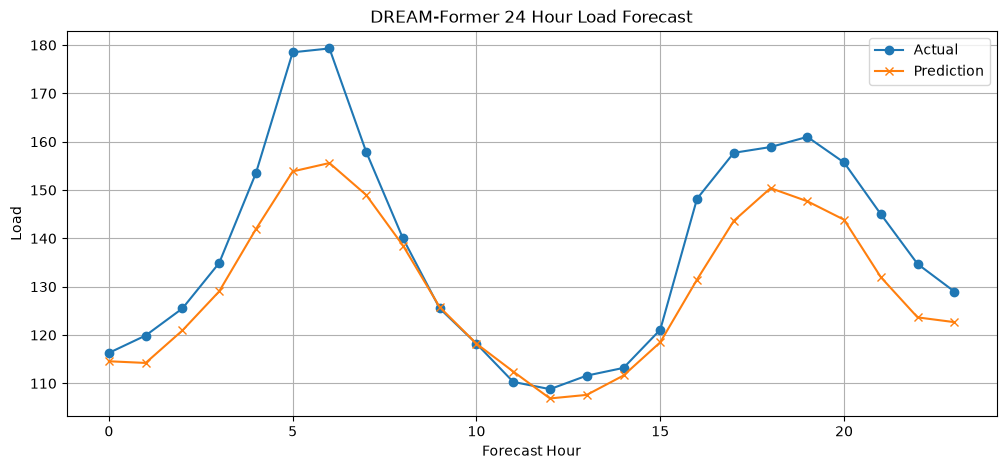

In [34]:
sample_id = 20


plt.figure(
    figsize=(12,5)
)


plt.plot(
    y_true[sample_id],
    marker="o",
    label="Actual"
)


plt.plot(
    pred[sample_id],
    marker="x",
    label="Prediction"
)


plt.xlabel(
    "Forecast Hour"
)

plt.ylabel(
    "Load"
)


plt.title(
    "DREAM-Former 24 Hour Load Forecast"
)


plt.legend()

plt.grid()

plt.show()

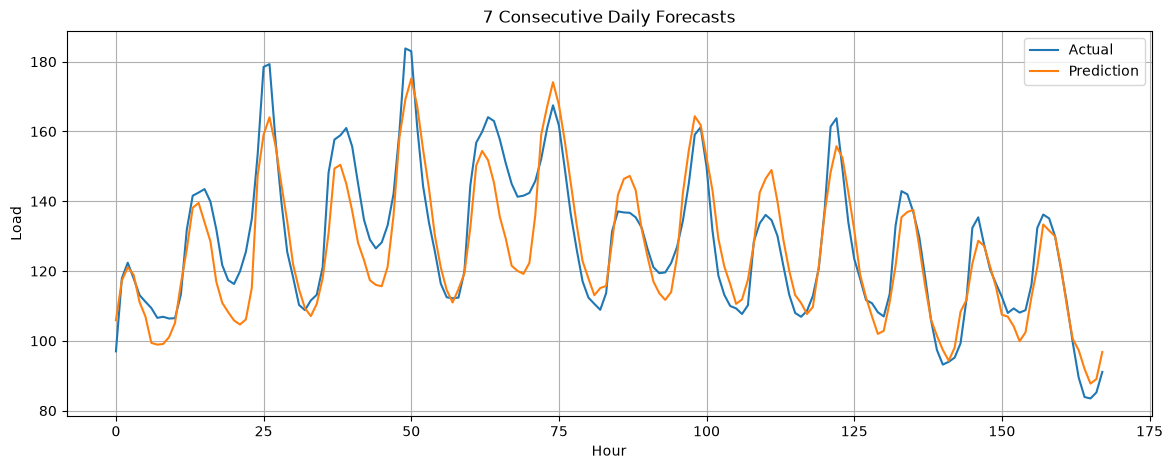

In [36]:
indices = [
    0,
    24,
    48,
    72,
    96,
    120,
    144
]


plt.figure(
    figsize=(14,5)
)


plt.plot(
    y_true[indices].flatten(),
    label="Actual"
)


plt.plot(
    pred[indices].flatten(),
    label="Prediction"
)


plt.xlabel(
    "Hour"
)


plt.ylabel(
    "Load"
)


plt.title(
    "7 Consecutive Daily Forecasts"
)


plt.legend()

plt.grid()

plt.show()

In [37]:
print(checkpoint.keys())

dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_loss', 'train_loss'])


In [38]:
print(checkpoint["epoch"])
print(checkpoint["val_loss"])

6
0.06528726622292941


In [39]:
print(
    pred.min(),
    pred.max()
)

print(
    y_true.min(),
    y_true.max()
)

62.900757 302.5617
16.100014 317.5


In [40]:
batch = next(iter(test_loader))

print(batch["demand"].shape)
print(batch["weather"].shape)
print(batch["calendar"].shape)
print(batch["target"].shape)

torch.Size([64, 168, 1])
torch.Size([64, 168, 25])
torch.Size([64, 168, 6])
torch.Size([64, 24])
